In [ ]:
# ==========================================================
# PROJECT: PREDICTIVE CLASSIFICATION USING RANDOM FOREST
# PHASE I: IMPORT LIBRARIES
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

from IPython.display import display

sns.set_theme(style="whitegrid")
print("All libraries imported successfully.")

All libraries imported successfully.


In [ ]:
# ==========================================================
# PHASE I: LOAD DATASET
# ==========================================================

dataset = load_breast_cancer(as_frame=True)

df = dataset.frame.copy()

# Rename the target column for clarity
df = df.rename(columns={"target": "diagnosis"})

# Convert numeric target labels into readable class names
df["diagnosis"] = df["diagnosis"].map({
    0: "malignant",
    1: "benign"
})

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


In [ ]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe().T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


In [ ]:
# ==========================================================
# PHASE II: DATA CLEANING
# ==========================================================

print("Missing values before cleaning:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Separate input features and target
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

# Handle missing numeric values using median imputation
imputer = SimpleImputer(strategy="median")
X_clean = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

print("\nMissing values after cleaning:",
      X_clean.isnull().sum().sum())

print("Feature matrix shape:", X_clean.shape)
print("Target shape:", y.shape)

Missing values before cleaning:
0

Duplicate rows: 0

Missing values after cleaning: 0
Feature matrix shape: (569, 30)
Target shape: (569,)


diagnosis
benign       357
malignant    212
Name: count, dtype: int64


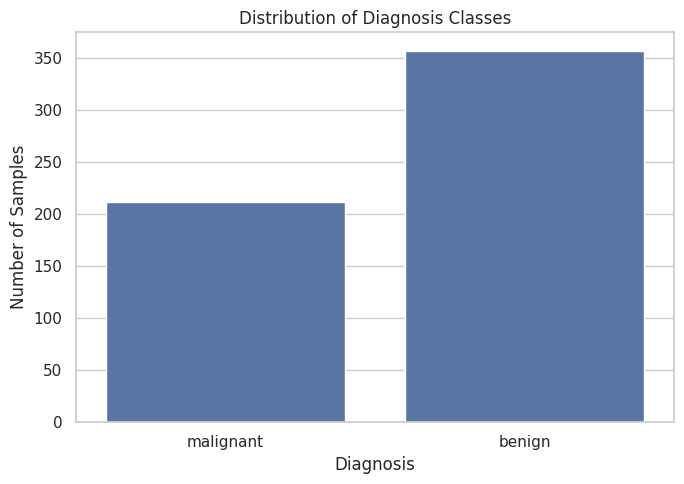

In [ ]:
# ==========================================================
# PHASE I: CLASS DISTRIBUTION
# ==========================================================

print(y.value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="diagnosis")
plt.title("Distribution of Diagnosis Classes")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

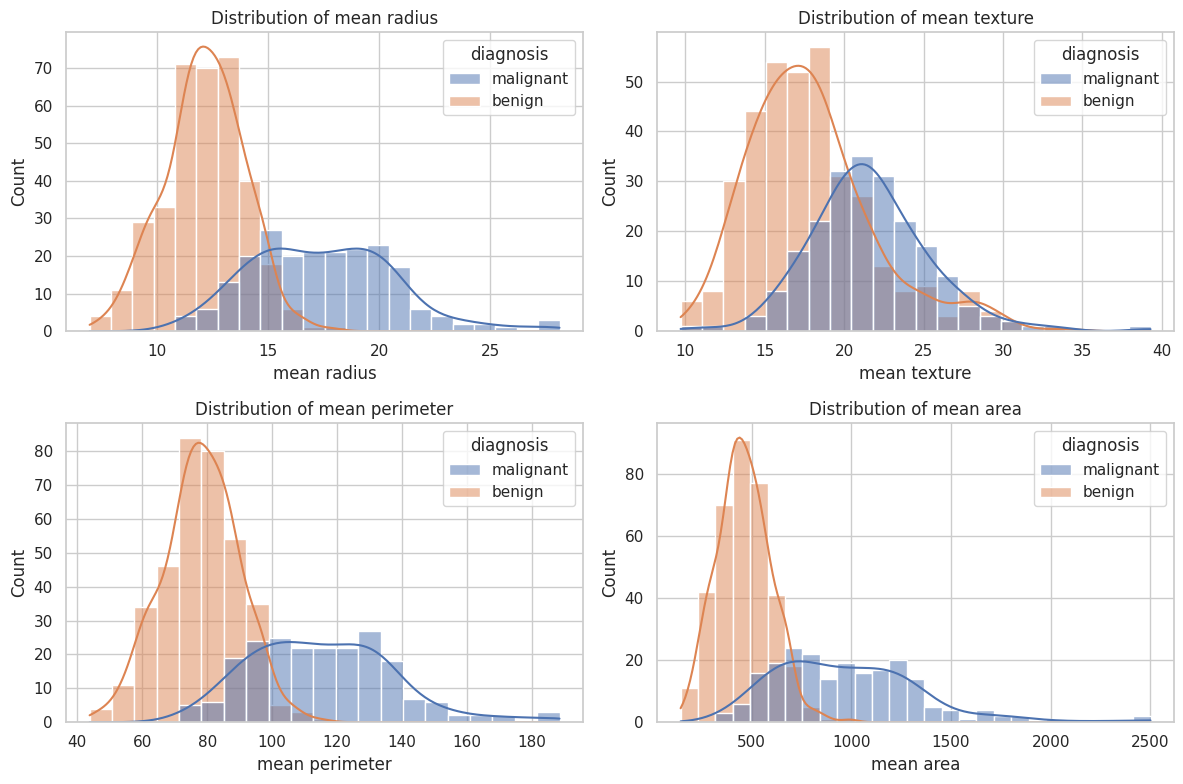

In [ ]:
# ==========================================================
# PHASE I: FEATURE DISTRIBUTIONS
# ==========================================================

selected_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(selected_features, axes.flatten()):
    sns.histplot(
        data=df,
        x=feature,
        hue="diagnosis",
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

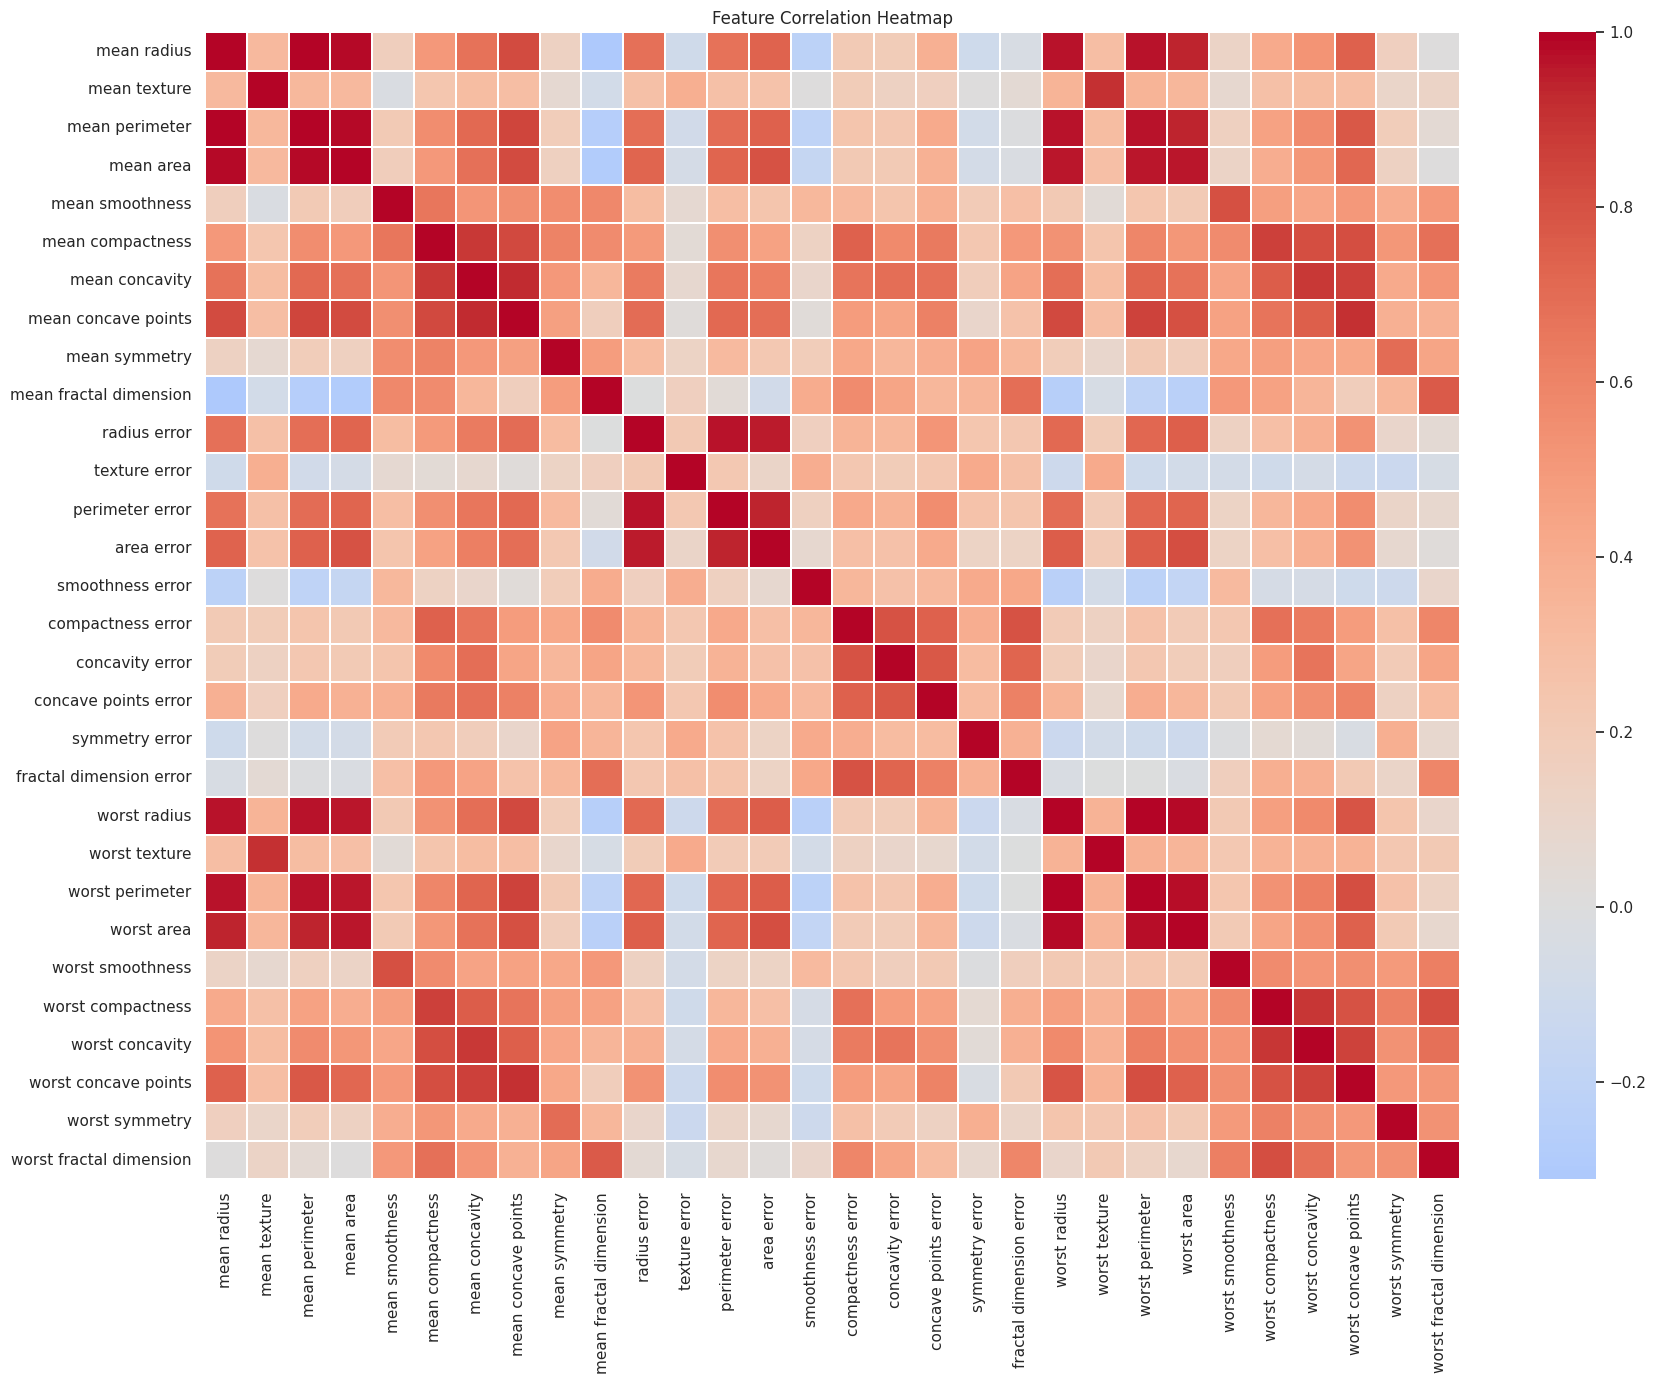

In [ ]:
# ==========================================================
# PHASE I: CORRELATION ANALYSIS
# ==========================================================

plt.figure(figsize=(18, 14))

correlation = X_clean.corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================================
# PHASE II: TRAIN-TEST SPLIT
# ==========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 455
Testing samples: 114

Training class distribution:
diagnosis
benign       285
malignant    170
Name: count, dtype: int64

Testing class distribution:
diagnosis
benign       72
malignant    42
Name: count, dtype: int64


In [ ]:
# ==========================================================
# PHASE III: MODEL DEVELOPMENT
# ==========================================================

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Train the ensemble model
rf_model.fit(X_train, y_train)

# Generate predictions on unseen test data
y_pred = rf_model.predict(X_test)

# Probability of the positive class for ROC-AUC
malignant_index = list(rf_model.classes_).index("malignant")
y_probability = rf_model.predict_proba(X_test)[:, malignant_index]

print("Random Forest model trained successfully!")
print("Number of trees:", rf_model.n_estimators)
print("Maximum tree depth:", rf_model.max_depth)

Random Forest model trained successfully!
Number of trees: 200
Maximum tree depth: 10


In [ ]:
# ==========================================================
# PHASE IV: EVALUATION METRICS
# ==========================================================

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label="malignant"
)

recall = recall_score(
    y_test, y_pred, pos_label="malignant"
)

f1 = f1_score(
    y_test, y_pred, pos_label="malignant"
)

roc_auc = roc_auc_score(
    (y_test == "malignant").astype(int),
    y_probability
)

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision (Malignant)",
        "Recall (Malignant)",
        "F1-Score (Malignant)",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

display(results.round(4))

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))

,Metric,Score
0,Accuracy,0.9649
1,Precision (Malignant),1.0000
2,Recall (Malignant),0.9048
3,F1-Score (Malignant),0.9500
4,ROC-AUC,0.9960



Detailed Classification Report:
              precision    recall  f1-score   support

      benign       0.95      1.00      0.97        72
   malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



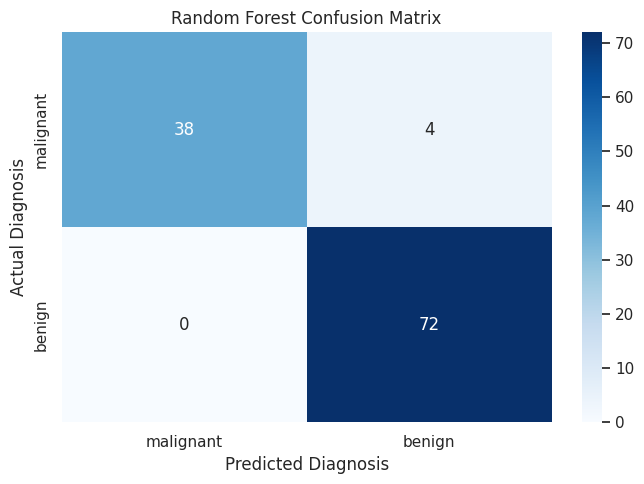

True Negatives: 38
False Positives: 4
False Negatives: 0
True Positives: 72


In [ ]:
# ==========================================================
# PHASE IV: CONFUSION MATRIX
# ==========================================================

labels = ["malignant", "benign"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Diagnosis")
plt.ylabel("Actual Diagnosis")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# Extract counts for malignant as the positive class
tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

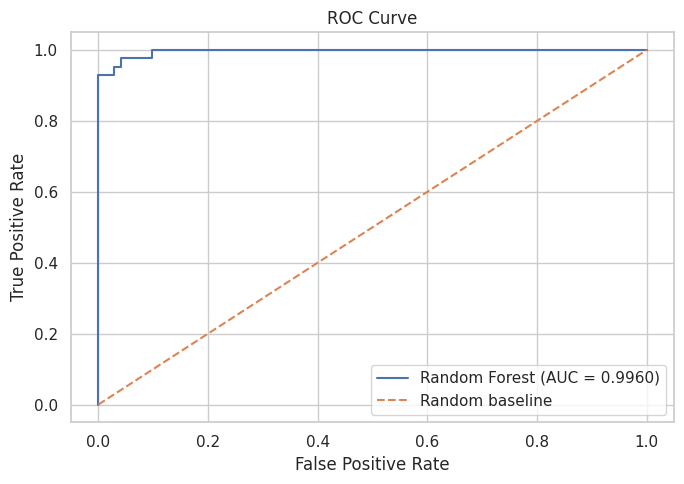

ROC-AUC Score: 0.9960


In [ ]:
# ==========================================================
# PHASE IV: ROC CURVE
# ==========================================================

y_test_binary = (y_test == "malignant").astype(int)

fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    y_probability
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"ROC-AUC Score: {roc_auc:.4f}")

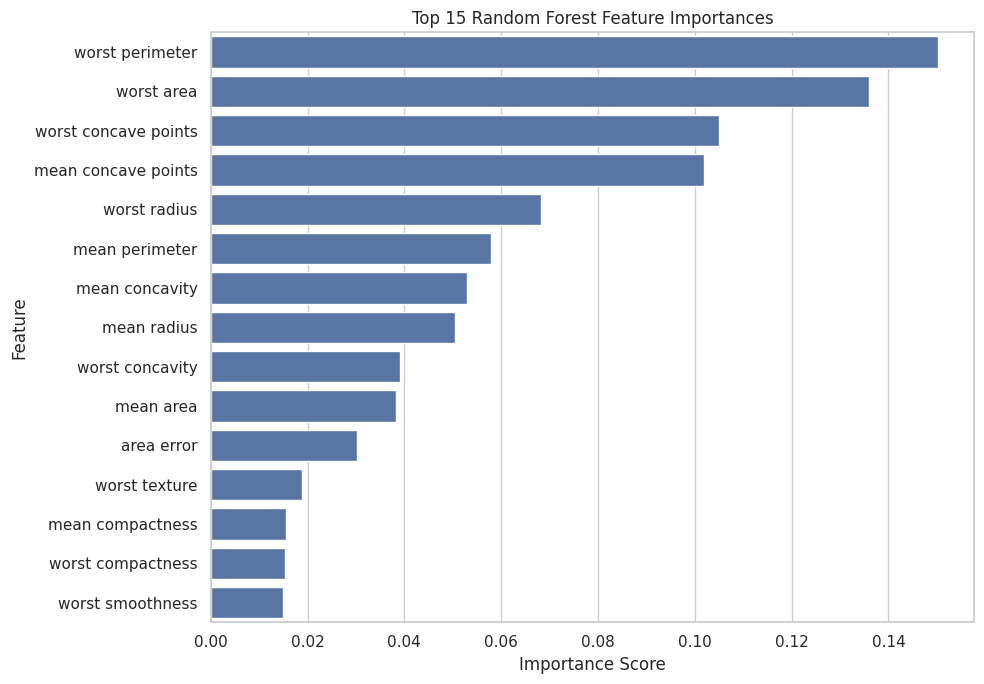

,Feature,Importance
22,worst perimeter,0.1502
23,worst area,0.1360
27,worst concave points,0.1051
7,mean concave points,0.1018
20,worst radius,0.0683
2,mean perimeter,0.0579
6,mean concavity,0.0530
0,mean radius,0.0505
26,worst concavity,0.0392
3,mean area,0.0383


In [ ]:
# ==========================================================
# PHASE IV: FEATURE IMPORTANCE
# ==========================================================

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

display(importance_df.head(15).round(4))

In [ ]:
# ==========================================================
# FINAL: EXPORT RESULTS AND VISUALIZATIONS
# ==========================================================

results.to_csv("evaluation_metrics.csv", index=False)
importance_df.to_csv("feature_importance.csv", index=False)

print("Saved files:")
print("1. evaluation_metrics.csv")
print("2. feature_importance.csv")
print("3. confusion_matrix.png")
print("4. roc_curve.png")
print("5. feature_importance.png")

Saved files:
1. evaluation_metrics.csv
2. feature_importance.csv
3. confusion_matrix.png
4. roc_curve.png
5. feature_importance.png
